In [ ]:
# Import Libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_proper_names_of_exoplanets"

headers = {
    'User-Agent': (
        'MyScraperBot/1.0 (https://example.com/contact; myemail@example.com)'
    )
}

response = requests.get(url, headers = headers)

print(response.status_code)

200


In [ ]:
soup = BeautifulSoup(response.text, "html.parser")

print("Page title:")
print(soup.title.get_text(strip=True) if soup.title else "Title not found")

Page title:
List of proper names of exoplanets - Wikipedia


In [ ]:
print("First 10 headings:")

headings = soup.find_all(["h1", "h2", "h3"])

for heading in headings[:10]:
    print(heading.get_text(" ", strip=True))

First 10 headings:
Contents
List of proper names of exoplanets
Naming
Questionable planets
List
See also
References
External links


In [ ]:
tables = pd.read_html(response.text)

print("Number of tables found:", len(tables))

/tmp/ipykernel_1308/4081976331.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


Number of tables found: 3


In [ ]:
for i, table in enumerate(tables):
    print(f"\nTable {i + 1}")
    display(table.head())


Table 1


,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,Spe,"""Hope"" (Latin)",14 Andromedae (Veritate),1.16[12],3.559[12],186.79[12],0.775[12],radial vel.,2008,248,0.898[13],4483[13],2015 NameExoWorlds
1,Arion,Ancient Greek poet,18 Delphini (Musica),9.207[14],NaN,993.3[15],2.476[14],radial vel.,2008[15],245[16],2.35[17],5071[17],2015 NameExoWorlds
2,Arkas,Son of Zeus and Callisto in Greek myth,41 Lyncis (Intercrus),1.654[18],NaN,183.93[18],0.648[18],radial vel.,2008[19][better source needed],276[20],1.07[18],4797,2015 NameExoWorlds
3,Orbitar,Neologism,42 Draconis (Fafnir),3.88,NaN,479.1,1.19,radial vel.,2008,317.3,0.98,4200,2015 NameExoWorlds Later disproven (see text)
4,Taphao Thong,Thai folktale character,47 Ursae Majoris (Chalawan),2.53,NaN,1078,2.1,radial vel.,1996,45.9,1.03,5892,2015 NameExoWorlds



Table 2


,vteExoplanet,vteExoplanet.1,vteExoplanet.2
0,Main topics,Planet Definition IAU Exoplanet orbital and ph...,NaN
1,Sizes and types,Terrestrial Carbon planet Catastrophically eva...,NaN
2,Terrestrial,Carbon planet Catastrophically evaporating pla...,NaN
3,Gaseous,Eccentric Jupiter Helium planet Hot Jupiter Ho...,NaN
4,Other types,Brown dwarf Chthonian planet Circumbinary plan...,NaN



Table 3


,0,1
0,Terrestrial,Carbon planet Catastrophically evaporating pla...
1,Gaseous,Eccentric Jupiter Helium planet Hot Jupiter Ho...
2,Other types,Brown dwarf Chthonian planet Circumbinary plan...


In [ ]:
# Here, we will select the first table as it contains useful information about exoplanets

In [ ]:
df = tables[0].copy()
df.head()

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,Spe,"""Hope"" (Latin)",14 Andromedae (Veritate),1.16[12],3.559[12],186.79[12],0.775[12],radial vel.,2008,248,0.898[13],4483[13],2015 NameExoWorlds
1,Arion,Ancient Greek poet,18 Delphini (Musica),9.207[14],NaN,993.3[15],2.476[14],radial vel.,2008[15],245[16],2.35[17],5071[17],2015 NameExoWorlds
2,Arkas,Son of Zeus and Callisto in Greek myth,41 Lyncis (Intercrus),1.654[18],NaN,183.93[18],0.648[18],radial vel.,2008[19][better source needed],276[20],1.07[18],4797,2015 NameExoWorlds
3,Orbitar,Neologism,42 Draconis (Fafnir),3.88,NaN,479.1,1.19,radial vel.,2008,317.3,0.98,4200,2015 NameExoWorlds Later disproven (see text)
4,Taphao Thong,Thai folktale character,47 Ursae Majoris (Chalawan),2.53,NaN,1078,2.1,radial vel.,1996,45.9,1.03,5892,2015 NameExoWorlds


In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (164, 13)


In [ ]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Name of planet', 'Eponym', 'Name of star', 'Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Discovery Method', 'Disc. year', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)', 'Remarks']


In [ ]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Name of planet        164 non-null    object
 1   Eponym                164 non-null    object
 2   Name of star          164 non-null    object
 3   Mass (MJ)             162 non-null    object
 4   Radius (RJ)           72 non-null     object
 5   Period (days)         161 non-null    object
 6   Semi-major axis (AU)  161 non-null    object
 7   Discovery Method      164 non-null    object
 8   Disc. year            164 non-null    object
 9   Distance (ly)         164 non-null    object
 10  Host star mass (M☉)   164 non-null    object
 11  Host star temp. (K)   155 non-null    object
 12  Remarks               164 non-null    object
dtypes: object(13)
memory usage: 16.8+ KB


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Name of planet           0
Eponym                   0
Name of star             0
Mass (MJ)                2
Radius (RJ)             92
Period (days)            3
Semi-major axis (AU)     3
Discovery Method         0
Disc. year               0
Distance (ly)            0
Host star mass (M☉)      0
Host star temp. (K)      9
Remarks                  0
dtype: int64


In [ ]:
# Save the scraped dataset

df.to_csv("exoplanet_data.csv", index=False)

In [ ]:
# Make a copy so the original scraped data stays unchanged

clean_df = df.copy()

# Columns that should contain numeric values

numeric_columns = [
    "Mass (MJ)",
    "Radius (RJ)",
    "Period (days)",
    "Semi-major axis (AU)",
    "Disc. year",
    "Distance (ly)",
    "Host star mass (M☉)",
    "Host star temp. (K)"
]

# Remove citation markers and convert values to numbers

for column in numeric_columns:
    clean_df[column] = (
        clean_df[column]
        .astype(str)
        .str.replace(r"\[\d+\]", "", regex=True)
        .str.strip()
    )

    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

In [ ]:
print("Updated data types:")
print(clean_df[numeric_columns].dtypes)

Updated data types:
Mass (MJ)               float64
Radius (RJ)             float64
Period (days)           float64
Semi-major axis (AU)    float64
Disc. year              float64
Distance (ly)           float64
Host star mass (M☉)     float64
Host star temp. (K)     float64
dtype: object


In [ ]:
clean_df.head()

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,Spe,"""Hope"" (Latin)",14 Andromedae (Veritate),1.160,3.559,186.79,0.775,radial vel.,2008.0,248.0,0.898,4483.0,2015 NameExoWorlds
1,Arion,Ancient Greek poet,18 Delphini (Musica),9.207,NaN,993.30,2.476,radial vel.,2008.0,245.0,2.350,5071.0,2015 NameExoWorlds
2,Arkas,Son of Zeus and Callisto in Greek myth,41 Lyncis (Intercrus),1.654,NaN,183.93,0.648,radial vel.,NaN,276.0,1.070,4797.0,2015 NameExoWorlds
3,Orbitar,Neologism,42 Draconis (Fafnir),3.880,NaN,479.10,1.190,radial vel.,2008.0,317.3,0.980,4200.0,2015 NameExoWorlds Later disproven (see text)
4,Taphao Thong,Thai folktale character,47 Ursae Majoris (Chalawan),2.530,NaN,1078.00,2.100,radial vel.,1996.0,45.9,1.030,5892.0,2015 NameExoWorlds


In [ ]:
print("Missing values after numeric conversion:")
print(clean_df.isnull().sum())

Missing values after numeric conversion:
Name of planet           0
Eponym                   0
Name of star             0
Mass (MJ)                3
Radius (RJ)             92
Period (days)            3
Semi-major axis (AU)     3
Discovery Method         0
Disc. year               1
Distance (ly)            0
Host star mass (M☉)      0
Host star temp. (K)      9
Remarks                  0
dtype: int64


In [ ]:
# Create a list of numeric and text columns

numeric_columns = clean_df.select_dtypes(include="number").columns
text_columns = clean_df.select_dtypes(include="object").columns

# Fill missing numeric values with the median

for column in numeric_columns:
    clean_df[column] = clean_df[column].fillna(
        clean_df[column].median()
    )

# Fill missing text values with the mode

for column in text_columns:
    if clean_df[column].isnull().sum() > 0:
        clean_df[column] = clean_df[column].fillna(
            clean_df[column].mode()[0]
        )

print("Missing values remaining:")
print(clean_df.isnull().sum())

Missing values remaining:
Name of planet          0
Eponym                  0
Name of star            0
Mass (MJ)               0
Radius (RJ)             0
Period (days)           0
Semi-major axis (AU)    0
Discovery Method        0
Disc. year              0
Distance (ly)           0
Host star mass (M☉)     0
Host star temp. (K)     0
Remarks                 0
dtype: int64


In [ ]:
# Save the clean dataset that we are going to use

clean_df.to_csv("exoplanet_cleaned_data.csv", index=False)

In [ ]:
# Select numerical columns for statistical analysis

numeric_df = clean_df.select_dtypes(include="number")

print("Numerical columns:")
print(numeric_df.columns.tolist())

print("\nNumber of numerical columns:", len(numeric_df.columns))

Numerical columns:
['Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Disc. year', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)']

Number of numerical columns: 8


In [ ]:
print("Statistical summary:")
print(numeric_df.describe())

Statistical summary:
        Mass (MJ)  Radius (RJ)  Period (days)  Semi-major axis (AU)  \
count  164.000000   164.000000     164.000000            164.000000   
mean     1.625750     1.115669    3685.898725             17.795180   
std      1.912575     0.328946   43360.562781            195.586979   
min      0.001720     0.064100       0.321962              0.006220   
25%      0.460000     1.135500       4.103346              0.052225   
50%      1.077000     1.135500      25.800000              0.233000   
75%      2.022500     1.135500     384.550000              1.222500   
max     10.250000     3.559000  555530.000000           2500.000000   

        Disc. year  Distance (ly)  Host star mass (M☉)  Host star temp. (K)  
count   164.000000     164.000000           164.000000           164.000000  
mean   2007.768293     409.939305             1.149927          5878.270732  
std       5.230394     439.158970             0.402916          3253.352334  
min    1992.000000      10.

In [ ]:
statistics = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Variance": numeric_df.var(),
    "Standard Deviation": numeric_df.std()
})

statistics

,Mean,Median,Mode,Variance,Standard Deviation
Mass (MJ),1.625750,1.0770,1.0770,3.657943e+00,1.912575
Radius (RJ),1.115669,1.1355,1.1355,1.082052e-01,0.328946
Period (days),3685.898725,25.8000,25.8000,1.880138e+09,43360.562781
Semi-major axis (AU),17.795180,0.2330,0.2330,3.825427e+04,195.586979
Disc. year,2007.768293,2009.0000,2011.0000,2.735703e+01,5.230394
Distance (ly),409.939305,263.5500,40.9000,1.928606e+05,439.158970
Host star mass (M☉),1.149927,1.1000,0.9100,1.623416e-01,0.402916
Host star temp. (K),5878.270732,5510.0000,5510.0000,1.058430e+07,3253.352334


In [ ]:
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1
print("Interquartile Range (IQR):")
print(IQR)

Interquartile Range (IQR):
Mass (MJ)                 1.562500
Radius (RJ)               0.000000
Period (days)           380.446654
Semi-major axis (AU)      1.170275
Disc. year                6.000000
Distance (ly)           405.432500
Host star mass (M☉)       0.412500
Host star temp. (K)     931.000000
dtype: float64


In [ ]:
# Visualisation

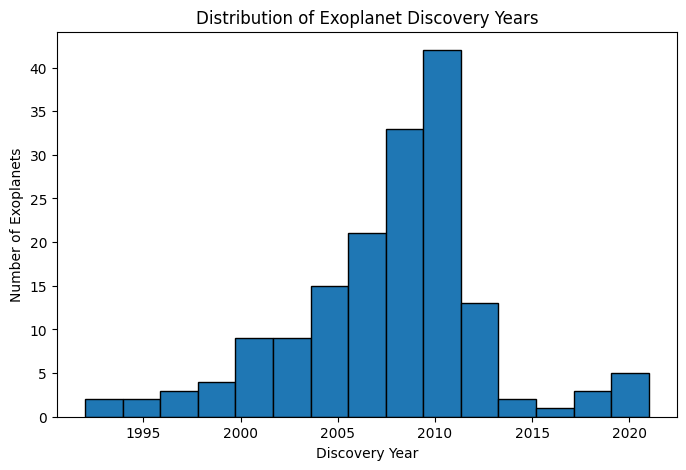

In [ ]:
# Histogram

plt.figure(figsize=(8, 5))

plt.hist(clean_df["Disc. year"], bins=15, edgecolor="black")

plt.title("Distribution of Exoplanet Discovery Years")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Exoplanets")

plt.show()

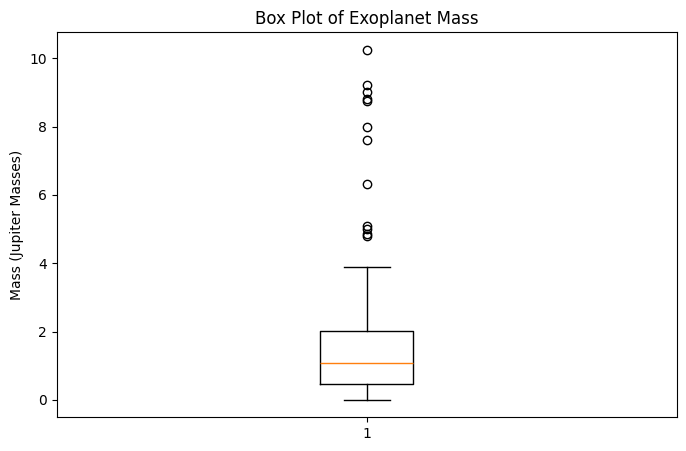

In [ ]:
# Box plot

plt.figure(figsize=(8, 5))

plt.boxplot(clean_df["Mass (MJ)"])

plt.title("Box Plot of Exoplanet Mass")
plt.ylabel("Mass (Jupiter Masses)")

plt.show()

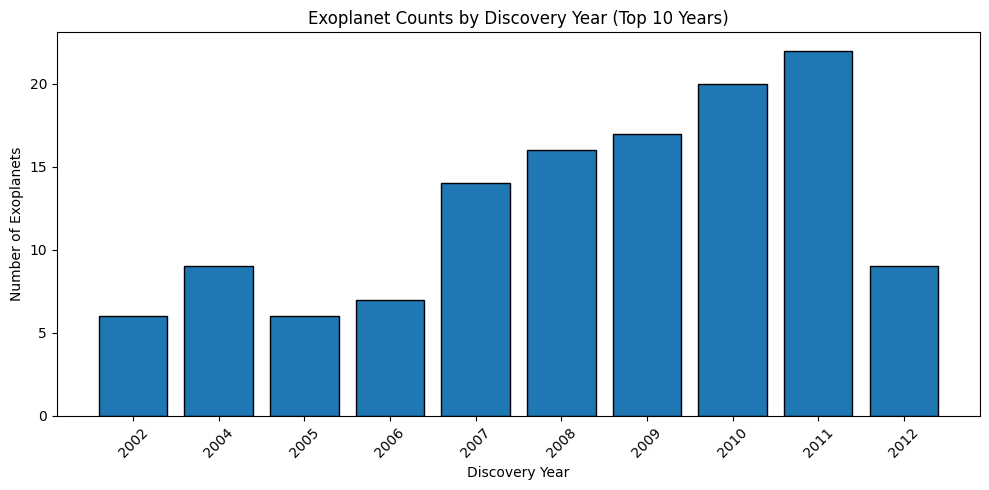

In [ ]:
# Bar chart

year_counts = clean_df["Disc. year"].value_counts().head(10)
year_counts = year_counts.sort_index()

plt.figure(figsize=(10, 5))

plt.bar(year_counts.index.astype(int).astype(str),
        year_counts.values,
        edgecolor="black")

plt.title("Exoplanet Counts by Discovery Year (Top 10 Years)")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Exoplanets")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

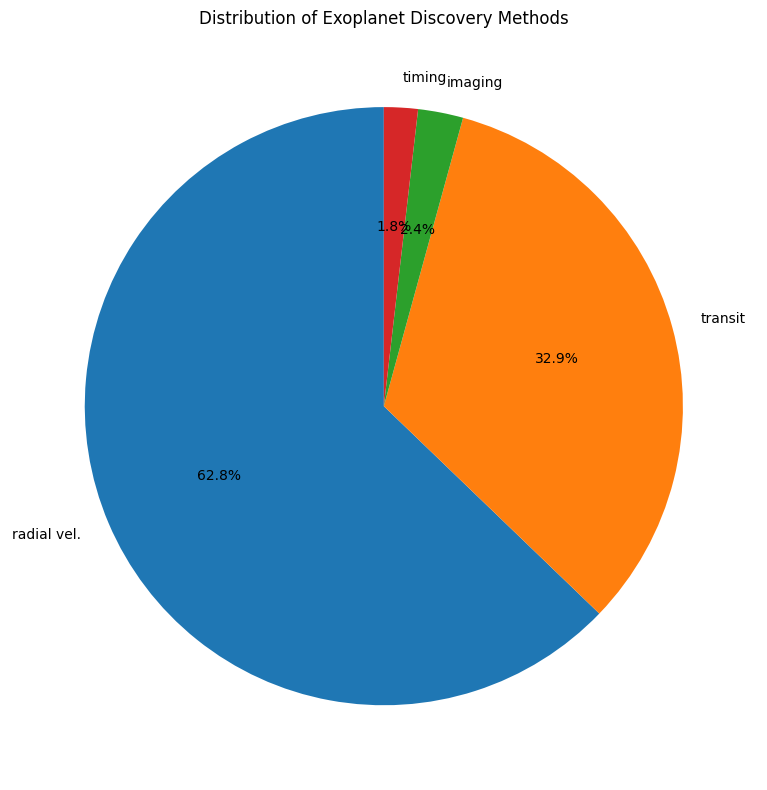

In [ ]:
# Pie Chart

method_counts = clean_df["Discovery Method"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    method_counts,
    labels=method_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Exoplanet Discovery Methods")
plt.tight_layout()
plt.show()

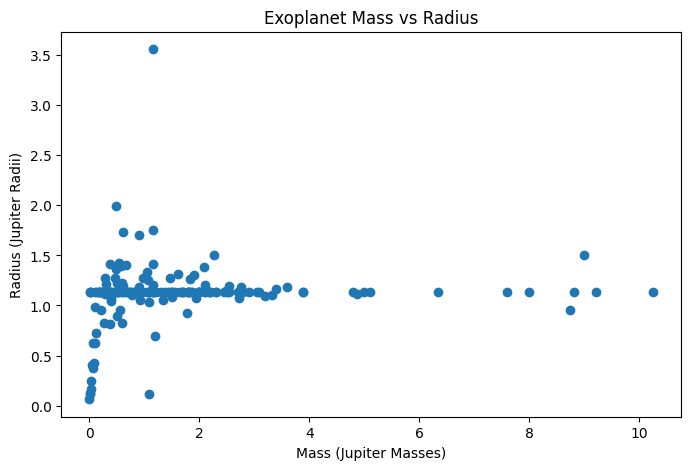

In [ ]:
# Scatter Plot

plt.figure(figsize=(8, 5))

plt.scatter(clean_df["Mass (MJ)"], clean_df["Radius (RJ)"])

plt.title("Exoplanet Mass vs Radius")
plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Radius (Jupiter Radii)")

plt.show()

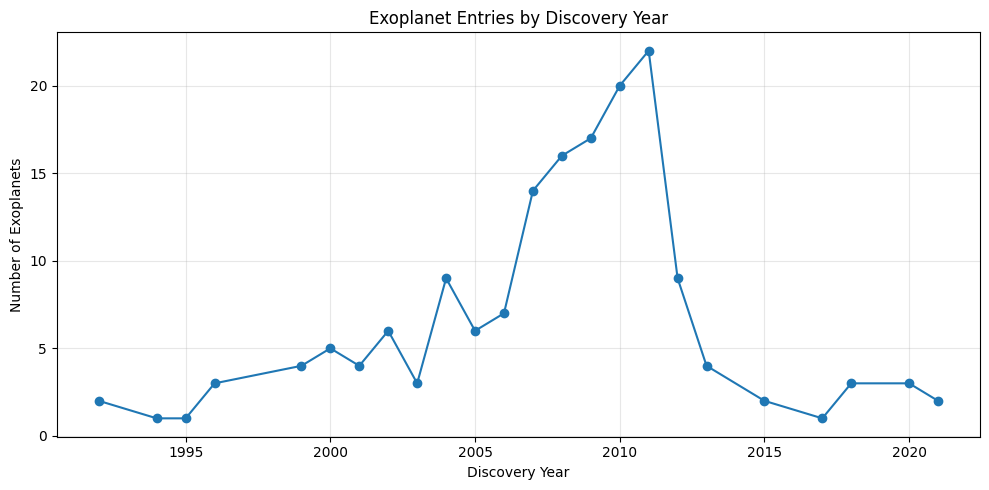

In [ ]:
# Line Chart

yearly_counts = clean_df.groupby("Disc. year").size().sort_index()

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker="o",
    linestyle="-"
)

plt.title("Exoplanet Entries by Discovery Year")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Exoplanets")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Probability Distribution and Sampling

In [ ]:
# Simple Random Sampling

sample1 = clean_df.sample(n=20, random_state=1)
sample1

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
44,Guarani,"Guaraní people of southern Brazil, Paraguay, U...",HD 23079 (Tupi),2.450,1.1355,730.600000,1.59600,radial vel.,2001.0,114.0,1.100,5848.0,2019 NameExoWorlds Brazil
47,Nakanbé,Nakanbé river in Burkina Faso and Ghana,HD 30856 A (Mouhoun),1.800,1.1355,912.000000,2.00000,radial vel.,2011.0,385.2,1.350,4982.0,2019 NameExoWorlds Burkina Faso
162,Catalineta,character from Mallorcan folktale,WASP-166 (Filetdor),0.101,0.6300,5.443540,0.06410,transit,2018.0,373.0,1.190,6050.0,2022 NameExoWorlds[23] Spain
66,Bélisama,"Belisama, Gaulish goddess likened to the Roman...",HD 8574 (Bélénos),2.110,1.1355,227.550000,0.77000,radial vel.,2003.0,144.0,1.170,6080.0,2019 NameExoWorlds France
157,Banksia,genus of plants,WASP-19 (Wattle),1.154,1.4150,0.788839,0.01652,transit,2009.0,869.0,0.965,5616.0,2022 NameExoWorlds[23] Australia
11,Harriot,English astronomer,55 Cancri A (Copernicus),0.141,1.1355,262.000000,0.78800,radial vel.,2007.0,40.9,0.910,5196.0,2015 NameExoWorlds
78,Noifasui,"""revolve around"" in the Nias language",HD 117618 (Dofida),0.174,1.1355,25.800000,0.18000,radial vel.,2004.0,124.0,1.050,5861.0,2019 NameExoWorlds Indonesia
35,Bocaprins,Boca Prins beach in Arikok National Park,WASP-39 (Malmok),0.280,1.2700,4.055259,0.04860,transit,2011.0,750.2,0.930,5400.0,2019 NameExoWorlds Aruba
99,Bagan,"Bagan, ancient city in Myanmar",HD 18742 (Ayeyarwady),3.400,1.1660,766.000000,1.82000,radial vel.,2011.0,440.0,1.360,4940.0,2019 NameExoWorlds Myanmar
14,Dagon,Fertility god of Levantine mythology,Fomalhaut A,1.077,1.1355,555530.000000,160.00000,imaging,2008.0,25.1,2.000,5510.0,2015 NameExoWorlds Later disproven (see text)


In [ ]:
# Random Sampling With Replacement

sample2 = clean_df.sample(n=20, replace=True, random_state=1)
sample2

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
37,Sissi,Character from the 1955 Austrian film Sissi,HAT-P-14 (Franz),1.15000,1.2000,4.627657,0.059400,transit,2010.0,668.60,1.386,6600.0,2019 NameExoWorlds Austria
140,Mulchatna,"Mulchatna River in southwestern Alaska, United...",HD 17156 (Nushagak),3.19500,1.0950,21.216398,0.162300,transit,2007.0,255.20,1.275,6079.0,2019 NameExoWorlds United States
72,Indépendance,Haitian Declaration of Independence,HD 1502 (Citadelle),2.75000,1.1830,428.500000,1.262000,radial vel.,2011.0,518.60,1.460,4947.0,2019 NameExoWorlds Haiti
137,Tryzub,"Tryzub, golden trident on the coat of arms of ...",HAT-P-15 (Berehynia),1.94600,1.0720,10.863502,0.096400,transit,2010.0,620.00,1.013,5568.0,2019 NameExoWorlds Ukraine
133,Agouto,Highest mountain in Togo,WASP-64 (Atakoraka),1.20000,0.7000,1.600000,0.233000,transit,2011.0,1219.51,0.990,5550.0,2019 NameExoWorlds Togo
79,Kavian,"""relating to Kaveh"" from the epic poem Shahnam...",HD 175541 (Kaveh),0.61000,1.1355,297.300000,1.030000,radial vel.,2007.0,417.50,1.650,5060.0,2019 NameExoWorlds Iran
144,Tahay,Chilean wildflower,Gliese 367 (Añañuca),0.00172,0.0641,0.321962,0.007100,transit,2021.0,30.70,0.454,3522.0,2022 NameExoWorlds[23] Chile
129,Ugarit,City where scribes devised the Ugaritic alphabet,HD 218566 (Ebla),0.21000,1.1355,225.700000,0.687300,radial vel.,2010.0,97.65,0.850,4820.0,2019 NameExoWorlds Syria
71,Koyopaʼ,"""lightning"" in the Kʼicheʼ language",WASP-22 (Tojil),0.61700,1.1990,3.532731,0.046980,transit,2010.0,978.50,1.100,6000.0,2019 NameExoWorlds Guatemala
134,Ramajay,"""to sing and make music"" in Trinidadian Creole",HD 96063 (Dingolay),0.90000,1.1355,361.100000,0.990000,radial vel.,2011.0,515.00,1.020,5148.0,2019 NameExoWorlds Trinidad and Tobago


In [ ]:
# Random Sampling Without Replacement

sample3 = clean_df.sample(n=20, replace=False, random_state=1)
sample3

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
44,Guarani,"Guaraní people of southern Brazil, Paraguay, U...",HD 23079 (Tupi),2.450,1.1355,730.600000,1.59600,radial vel.,2001.0,114.0,1.100,5848.0,2019 NameExoWorlds Brazil
47,Nakanbé,Nakanbé river in Burkina Faso and Ghana,HD 30856 A (Mouhoun),1.800,1.1355,912.000000,2.00000,radial vel.,2011.0,385.2,1.350,4982.0,2019 NameExoWorlds Burkina Faso
162,Catalineta,character from Mallorcan folktale,WASP-166 (Filetdor),0.101,0.6300,5.443540,0.06410,transit,2018.0,373.0,1.190,6050.0,2022 NameExoWorlds[23] Spain
66,Bélisama,"Belisama, Gaulish goddess likened to the Roman...",HD 8574 (Bélénos),2.110,1.1355,227.550000,0.77000,radial vel.,2003.0,144.0,1.170,6080.0,2019 NameExoWorlds France
157,Banksia,genus of plants,WASP-19 (Wattle),1.154,1.4150,0.788839,0.01652,transit,2009.0,869.0,0.965,5616.0,2022 NameExoWorlds[23] Australia
11,Harriot,English astronomer,55 Cancri A (Copernicus),0.141,1.1355,262.000000,0.78800,radial vel.,2007.0,40.9,0.910,5196.0,2015 NameExoWorlds
78,Noifasui,"""revolve around"" in the Nias language",HD 117618 (Dofida),0.174,1.1355,25.800000,0.18000,radial vel.,2004.0,124.0,1.050,5861.0,2019 NameExoWorlds Indonesia
35,Bocaprins,Boca Prins beach in Arikok National Park,WASP-39 (Malmok),0.280,1.2700,4.055259,0.04860,transit,2011.0,750.2,0.930,5400.0,2019 NameExoWorlds Aruba
99,Bagan,"Bagan, ancient city in Myanmar",HD 18742 (Ayeyarwady),3.400,1.1660,766.000000,1.82000,radial vel.,2011.0,440.0,1.360,4940.0,2019 NameExoWorlds Myanmar
14,Dagon,Fertility god of Levantine mythology,Fomalhaut A,1.077,1.1355,555530.000000,160.00000,imaging,2008.0,25.1,2.000,5510.0,2015 NameExoWorlds Later disproven (see text)


In [ ]:
# Fraction Sampling

sample4 = clean_df.sample(frac=0.20, random_state=1)
sample4

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
44,Guarani,"Guaraní people of southern Brazil, Paraguay, U...",HD 23079 (Tupi),2.4500,1.1355,730.600000,1.59600,radial vel.,2001.0,114.00,1.100,5848.0,2019 NameExoWorlds Brazil
47,Nakanbé,Nakanbé river in Burkina Faso and Ghana,HD 30856 A (Mouhoun),1.8000,1.1355,912.000000,2.00000,radial vel.,2011.0,385.20,1.350,4982.0,2019 NameExoWorlds Burkina Faso
162,Catalineta,character from Mallorcan folktale,WASP-166 (Filetdor),0.1010,0.6300,5.443540,0.06410,transit,2018.0,373.00,1.190,6050.0,2022 NameExoWorlds[23] Spain
66,Bélisama,"Belisama, Gaulish goddess likened to the Roman...",HD 8574 (Bélénos),2.1100,1.1355,227.550000,0.77000,radial vel.,2003.0,144.00,1.170,6080.0,2019 NameExoWorlds France
157,Banksia,genus of plants,WASP-19 (Wattle),1.1540,1.4150,0.788839,0.01652,transit,2009.0,869.00,0.965,5616.0,2022 NameExoWorlds[23] Australia
11,Harriot,English astronomer,55 Cancri A (Copernicus),0.1410,1.1355,262.000000,0.78800,radial vel.,2007.0,40.90,0.910,5196.0,2015 NameExoWorlds
78,Noifasui,"""revolve around"" in the Nias language",HD 117618 (Dofida),0.1740,1.1355,25.800000,0.18000,radial vel.,2004.0,124.00,1.050,5861.0,2019 NameExoWorlds Indonesia
35,Bocaprins,Boca Prins beach in Arikok National Park,WASP-39 (Malmok),0.2800,1.2700,4.055259,0.04860,transit,2011.0,750.20,0.930,5400.0,2019 NameExoWorlds Aruba
99,Bagan,"Bagan, ancient city in Myanmar",HD 18742 (Ayeyarwady),3.4000,1.1660,766.000000,1.82000,radial vel.,2011.0,440.00,1.360,4940.0,2019 NameExoWorlds Myanmar
14,Dagon,Fertility god of Levantine mythology,Fomalhaut A,1.0770,1.1355,555530.000000,160.00000,imaging,2008.0,25.10,2.000,5510.0,2015 NameExoWorlds Later disproven (see text)


In [ ]:
print("Sample size:", len(sample4))

Sample size: 33


In [ ]:
# Systematic Random Sampling

k = 5

systematic_sample = clean_df.iloc[::k]
systematic_sample

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,Spe,"""Hope"" (Latin)",14 Andromedae (Veritate),1.16000,3.5590,186.790000,0.775000,radial vel.,2008.0,248.0,0.898,4483.0,2015 NameExoWorlds
5,Taphao Kaew,Thai folktale character,47 Ursae Majoris (Chalawan),0.54000,1.1355,2391.000000,3.600000,radial vel.,2001.0,45.9,1.030,5892.0,2015 NameExoWorlds
10,Janssen,Dutch astronomer,55 Cancri A (Copernicus),0.02542,0.1700,0.736539,0.015440,radial vel.,2004.0,40.9,0.910,5196.0,2015 NameExoWorlds
15,Tadmor,Ancient Palmyrene Aramaic and modern Arabic na...,Gamma Cephei A (Errai),1.85000,1.1355,903.300000,2.050000,radial vel.,2003.0,45.0,1.400,5510.0,2015 NameExoWorlds
20,Dulcinea,Characters from Don Quixote,Mu Arae (Cervantes),0.03321,1.1355,9.630000,0.090940,radial vel.,2004.0,49.8,1.080,5807.0,2015 NameExoWorlds
25,Samh,Muslim astronomer,Upsilon Andromedae (Titawin),1.98100,1.1355,241.258000,0.827774,radial vel.,1999.0,43.9,1.300,5510.0,2015 NameExoWorlds
30,Phobetor,Greek myth,PSR B1257+12 (Lich),0.01230,1.1355,98.211400,0.460000,timing,1992.0,2300.0,1.400,28856.0,2015 NameExoWorlds
35,Bocaprins,Boca Prins beach in Arikok National Park,WASP-39 (Malmok),0.28000,1.2700,4.055259,0.048600,transit,2011.0,750.2,0.930,5400.0,2019 NameExoWorlds Aruba
40,Eburonia,"The Eburones, a prominent Celtic tribe",HD 49674 (Nervia),0.10000,0.9800,4.947390,0.058000,radial vel.,2002.0,133.0,1.070,5482.0,2019 NameExoWorlds Belgium
45,Mastika,"""gem/jewel"" in Malay",HD 179949 (Gumala),0.92000,1.0500,3.092500,0.045000,radial vel.,2000.0,88.1,1.280,6260.0,2019 NameExoWorlds Brunei


In [ ]:
print("Sample size:", len(systematic_sample))

Sample size: 33


In [ ]:
# Stratified Sampling

sample5 = clean_df.groupby("Discovery Method", group_keys=False).sample(frac=0.20, random_state=1)

sample5

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
163,Ahra,"""ocean"" in Korean",WD 0806−661 (Maru),8.00000,1.1355,25.800000,2500.000000,imaging,2011.0,62.70,0.6200,9552.0,2022 NameExoWorlds[23] South Korea
86,Buru,"""dust"" in the Dholuo language",HD 83443 (Kalausi),0.40000,1.0400,2.985720,0.040600,radial vel.,2002.0,142.00,0.9000,5460.0,2019 NameExoWorlds Kenya
41,Drukyul,Native name of Bhutan,HD 73534 (Gakyid),1.15000,1.1355,1800.000000,3.150000,radial vel.,2009.0,316.30,1.2900,4952.0,2019 NameExoWorlds Bhutan
76,Fold,"""earth/soil"" in Old Icelandic",HD 109246 (Funi),0.77000,1.1355,68.270000,0.330000,radial vel.,2010.0,214.00,1.0100,5844.0,2019 NameExoWorlds Iceland
103,Xolotlan,Second largest lake in Nicaragua,HD 4208 (Cocibolca),0.80400,1.1355,828.000000,1.650000,radial vel.,2001.0,111.00,0.8700,5571.0,2019 NameExoWorlds Nicaragua
45,Mastika,"""gem/jewel"" in Malay",HD 179949 (Gumala),0.92000,1.0500,3.092500,0.045000,radial vel.,2000.0,88.10,1.2800,6260.0,2019 NameExoWorlds Brunei
72,Indépendance,Haitian Declaration of Independence,HD 1502 (Citadelle),2.75000,1.1830,428.500000,1.262000,radial vel.,2011.0,518.60,1.4600,4947.0,2019 NameExoWorlds Haiti
69,Toge,"""earring"" in the Ewe language",HD 181720 (Sika),0.37000,1.1355,956.000000,1.780000,radial vel.,2009.0,183.00,0.9200,5781.0,2019 NameExoWorlds Ghana
118,Dopere,North Senegalese area containing the water sou...,HD 181342 (Belel),2.54000,1.1900,564.100000,1.592000,radial vel.,2010.0,360.70,1.6900,4945.0,2019 NameExoWorlds Senegal
36,Yanyan,"""boy"" in the Boon wurrung language",HD 38283 (Bubup),0.34000,1.1355,363.200000,1.020000,radial vel.,2011.0,123.00,1.0850,5945.0,2019 NameExoWorlds Australia


In [ ]:
print("Sample size:", len(sample5))

Sample size: 34


In [ ]:
# Cluster Sampling

clusters = np.random.choice(
    clean_df["Discovery Method"].unique(),
    size=2,
    replace=False
)

cluster_sample = clean_df[
    clean_df["Discovery Method"].isin(clusters)
]

print("Selected discovery methods:", clusters)

Selected discovery methods: ['timing' 'transit']


In [ ]:
cluster_sample

,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
28,Draugr,Norse myth,PSR B1257+12 (Lich),1.07700,1.1355,25.262000,0.190000,timing,1994.0,2300.000,1.4000,28856.0,2015 NameExoWorlds
29,Poltergeist,German folklore,PSR B1257+12 (Lich),0.01350,1.1355,66.541900,0.360000,timing,1992.0,2300.000,1.4000,28856.0,2015 NameExoWorlds
30,Phobetor,Greek myth,PSR B1257+12 (Lich),0.01230,1.1355,98.211400,0.460000,timing,1992.0,2300.000,1.4000,28856.0,2015 NameExoWorlds
35,Bocaprins,Boca Prins beach in Arikok National Park,WASP-39 (Malmok),0.28000,1.2700,4.055259,0.048600,transit,2011.0,750.200,0.9300,5400.0,2019 NameExoWorlds Aruba
37,Sissi,Character from the 1955 Austrian film Sissi,HAT-P-14 (Franz),1.15000,1.2000,4.627657,0.059400,transit,2010.0,668.600,1.3860,6600.0,2019 NameExoWorlds Austria
46,Bendida,"Bendis, a Thracian goddess",WASP-21 (Tangra),0.30000,1.2100,4.322513,0.052000,transit,2010.0,750.200,1.0100,5800.0,2019 NameExoWorlds Bulgaria
53,Ditsö̀,Name given to the first Bribri people by the g...,WASP-17 (Diwö),0.48600,1.9910,3.735438,0.051500,transit,2009.0,1338.570,1.2000,6650.0,2019 NameExoWorlds Costa Rica
54,Asye,Earth goddess from Akan mythology,WASP-15 (Nyamien),0.54200,1.4280,3.752066,0.049900,transit,2008.0,1005.000,1.1800,6300.0,2019 NameExoWorlds Côte d'Ivoire
58,Makropulos,Věc Makropulos by Czech playwright Karel Čapek,XO-5 (Absolutno),1.07700,1.0300,4.187754,0.048700,transit,2008.0,831.700,0.8800,5510.0,2019 NameExoWorlds Czechia
59,Surt,Ruler of Muspelheim from Norse mythology,HAT-P-29 (Muspelheim),0.77800,1.1070,5.723186,0.066700,transit,2011.0,1050.000,1.2070,6087.0,2019 NameExoWorlds Denmark


In [ ]:
# Population Mean

population_mean = clean_df["Mass (MJ)"].mean()

print("Population Mean:", population_mean)

Population Mean: 1.6257504268292682


In [ ]:
# Select 10 random exoplanets

random_sample = clean_df.sample(n=10, random_state=42)

print("Random Sample of 10 Exoplanets:")
random_sample

Random Sample of 10 Exoplanets:


,Name of planet,Eponym,Name of star,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Discovery Method,Disc. year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
135,Khomsa,Palm-shaped amulet popular in Tunisia,HD 192699 (Chechia),2.0960,1.2060,340.940000,1.06300,radial vel.,2007.0,220.0,1.380,5041.0,2019 NameExoWorlds Tunisia
115,Aumatex,God of the wind in Taíno mythology,HIP 12961 (Koeia),0.3500,1.1355,57.435000,0.13000,radial vel.,2009.0,75.0,0.670,5510.0,2019 NameExoWorlds Puerto Rico
131,Tanzanite,Tanzanite mineral,WASP-71 (Mpingo),2.2580,1.5000,2.903675,0.04631,transit,2012.0,700.0,1.572,6050.0,2019 NameExoWorlds Tanzania
55,Veles,"Veles, Slavic deity of earth, waters, and the ...",HD 75898 (Stribor),2.5100,1.1355,418.200000,1.19000,radial vel.,2007.0,262.8,1.280,6021.0,2019 NameExoWorlds Croatia
95,Cuptor,Baking and drying chamber formerly used in Mau...,WASP-72 (Diya),1.4610,1.2700,2.216742,0.03708,transit,2013.0,1108.0,1.386,6250.0,2019 NameExoWorlds Mauritius
29,Poltergeist,German folklore,PSR B1257+12 (Lich),0.0135,1.1355,66.541900,0.36000,timing,1992.0,2300.0,1.400,28856.0,2015 NameExoWorlds
157,Banksia,genus of plants,WASP-19 (Wattle),1.1540,1.4150,0.788839,0.01652,transit,2009.0,869.0,0.965,5616.0,2022 NameExoWorlds[23] Australia
51,Melquíades,Character from the novel One Hundred Years of ...,HD 93083 (Macondo),0.3700,1.1355,143.580000,0.47700,radial vel.,2005.0,94.3,0.700,4995.0,2019 NameExoWorlds Colombia
101,Nachtwacht,"The Night Watch, painting by Rembrandt",HAT-P-6 (Sterrennacht),1.0570,1.3300,3.853003,0.05235,transit,2007.0,650.0,1.290,6570.0,2019 NameExoWorlds Netherlands
145,Awohali,"""eagle"" in Cherokee",Gliese 436 (Noquisi),0.0700,0.3720,2.643883,0.02910,radial vel.,2004.0,31.9,0.470,3586.0,2022 NameExoWorlds[23] United States


In [ ]:
# Sample Mean

sample_mean = random_sample["Mass (MJ)"].mean()

print("Sample Mean:", sample_mean)

Sample Mean: 1.13395


In [ ]:
# Comparison b/w population and sample

comparison = pd.DataFrame({
    "Statistics": ["Size", "Mean", "Median", "Standard Deviation"],

    "Population": [
        len(clean_df),
        clean_df["Mass (MJ)"].mean(),
        clean_df["Mass (MJ)"].median(),
        clean_df["Mass (MJ)"].std()
    ],

    "Random Sample": [
        len(random_sample),
        random_sample["Mass (MJ)"].mean(),
        random_sample["Mass (MJ)"].median(),
        random_sample["Mass (MJ)"].std()
    ]
})

comparison

,Statistics,Population,Random Sample
0,Size,164.000000,10.00000
1,Mean,1.625750,1.13395
2,Median,1.077000,1.10550
3,Standard Deviation,1.912575,0.92984


In [ ]:
# Percentage Error

error = abs(
    (sample_mean - population_mean) / population_mean
) * 100

print("Percentage Error in Mean:", error, "%")

Percentage Error in Mean: 30.250671856715165 %


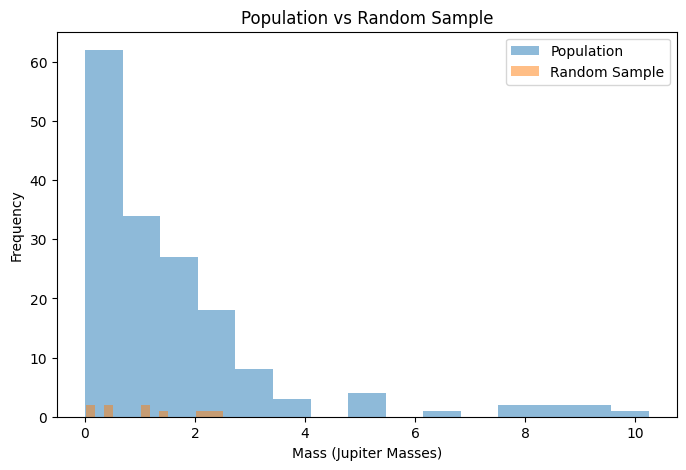

In [ ]:
# Compare the distributions

plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["Mass (MJ)"],
    bins=15,
    alpha=0.5,
    label="Population"
)

plt.hist(
    random_sample["Mass (MJ)"],
    bins=15,
    alpha=0.5,
    label="Random Sample"
)

plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Frequency")
plt.title("Population vs Random Sample")
plt.legend()

plt.show()

In [ ]:
# Repeated Sampling

mass_data = clean_df["Mass (MJ)"].dropna()

means = []

for i in range(100):
    sample = mass_data.sample(n=30, replace=True)
    means.append(sample.mean())

print("Number of sample means:", len(means))
print("Average of sample means:", np.mean(means))

Number of sample means: 100
Average of sample means: 1.6177393100000002


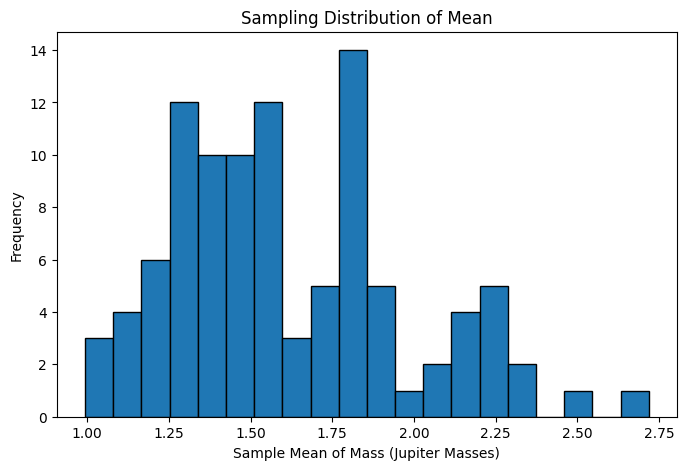

In [ ]:
# Plot Sampling Distribution

plt.figure(figsize=(8, 5))

plt.hist(means, bins=20, edgecolor="black")

plt.title("Sampling Distribution of Mean")
plt.xlabel("Sample Mean of Mass (Jupiter Masses)")
plt.ylabel("Frequency")

plt.show()

[18171.53545124 12034.37237021 18349.0399003   3822.76351447
  8636.61415042 28468.3125023   6898.17534016 26033.56371278
 12996.42893524  6757.02136731 17630.07278555 26037.45314913
  7529.33423739 15500.61826213 25418.52981992 11813.38401275
  3737.55419526 24640.98359748 18990.79692539  4200.38875863
 13209.36830322 26218.32867459 12269.59971701 16243.97616165
 14656.27670516 28776.81301267  7275.98211401 17618.31225184
  5429.04053016  7529.62219036 28163.94835376  7179.7064286
 12295.55132707 19761.82261397 23305.94864093  7860.0768627
  4167.99655374 13407.36190294 14495.63557039 16858.12846522
 26593.04883007 21731.48383696 17370.74205608 15231.13676252
 20605.13746328  6828.26228427 11126.41882994  7475.64192037
 11855.60195549 25598.02468224 18511.8714898   8262.78850154
 18548.71639483 17776.62667081  6708.99459364  3078.72650099
  3856.32247517  7402.99665743 27539.18850066 11663.5163974
 15781.19884773 23111.17266871 26842.44264825 10085.35486212
 18622.00390068 12953.20164

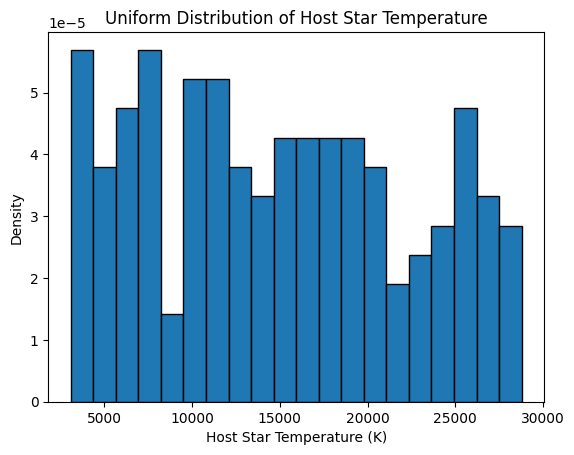

In [ ]:
# Uniform Distribution for Host Star Temperatures

from scipy.stats import uniform

data = clean_df["Host star temp. (K)"].dropna()

loc = data.min()
scale = data.max() - data.min()

uniform_data = uniform.rvs(loc=loc, scale=scale, size=len(data))

print(uniform_data)

print("Mean:", np.mean(uniform_data))
print("\nVariance:", np.var(uniform_data))

plt.hist(uniform_data, bins=20, density=True, edgecolor="black")
plt.title("Uniform Distribution of Host Star Temperature")
plt.xlabel("Host Star Temperature (K)")
plt.ylabel("Density")

plt.show()

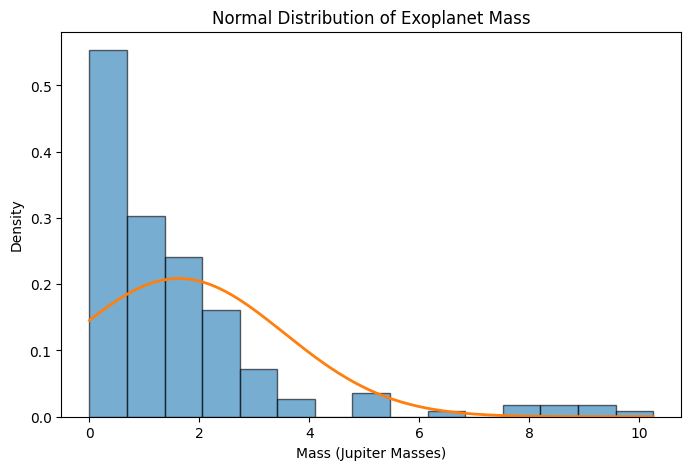

Mean: 1.6257504268292682
Standard Deviation: 1.912574991100866


In [ ]:
# Normal Distribution for Mass

from scipy.stats import norm

mass_data = clean_df["Mass (MJ)"].dropna()

mean = mass_data.mean()
std = mass_data.std()

plt.figure(figsize=(8, 5))

plt.hist(mass_data, bins=15, density=True, alpha=0.6,
         edgecolor="black")

x = np.linspace(mass_data.min(), mass_data.max(), 200)
y = norm.pdf(x, mean, std)

plt.plot(x, y, linewidth=2)

plt.title("Normal Distribution of Exoplanet Mass")
plt.xlabel("Mass (Jupiter Masses)")
plt.ylabel("Density")

plt.show()

print("Mean:", mean)
print("Standard Deviation:", std)

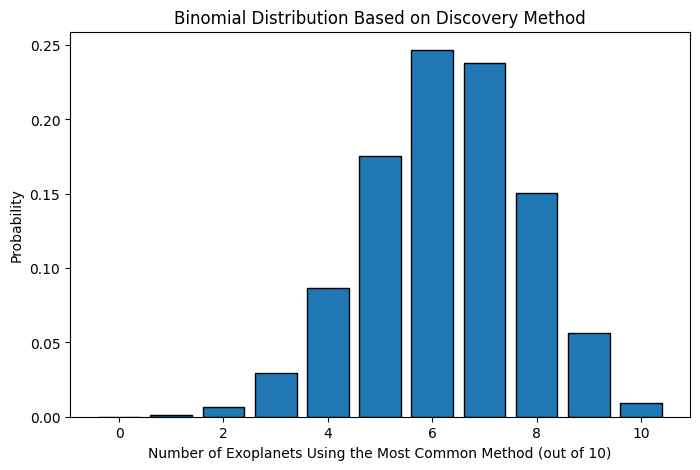

Most common method: radial vel.
Estimated probability: 0.6280487804878049


In [ ]:
# Binomial Distribution for Discovery Method

from scipy.stats import binom

method_counts = clean_df["Discovery Method"].value_counts()

most_common_method = method_counts.index[0]
p = method_counts.iloc[0] / len(clean_df)

n = 10
x = np.arange(0, n + 1)
probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(8, 5))

plt.bar(x, probabilities, edgecolor="black")

plt.title("Binomial Distribution Based on Discovery Method")
plt.xlabel("Number of Exoplanets Using the Most Common Method (out of 10)")
plt.ylabel("Probability")

plt.show()

print("Most common method:", most_common_method)
print("Estimated probability:", p)

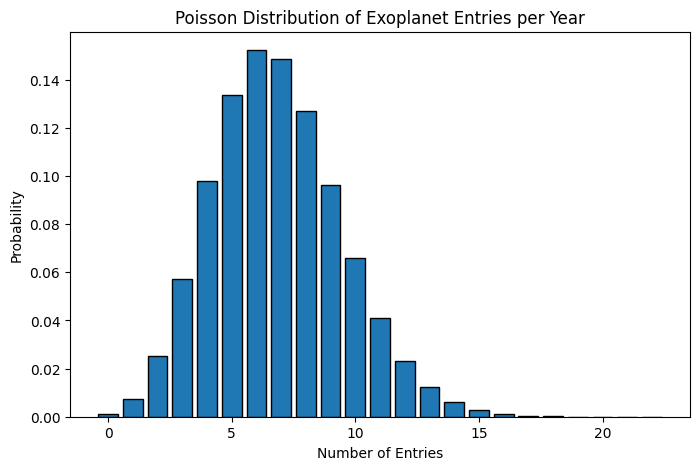

Estimated lambda: 6.833333333333333


In [ ]:
# Poisson Distribution for Entries per Discovery Year

from scipy.stats import poisson

year_counts = clean_df["Disc. year"].value_counts()
lam = year_counts.mean()

x = np.arange(0, int(year_counts.max()) + 1)
probabilities = poisson.pmf(x, lam)

plt.figure(figsize=(8, 5))

plt.bar(x, probabilities, edgecolor="black")

plt.title("Poisson Distribution of Exoplanet Entries per Year")
plt.xlabel("Number of Entries")
plt.ylabel("Probability")

plt.show()

print("Estimated lambda:", lam)

In [ ]:
# Central Limit Theorem

In [ ]:
# Select distance(ly)

distance_data = clean_df["Distance (ly)"].dropna()

# Calculate population statistics

population_mean = distance_data.mean()
population_std = distance_data.std()

print("Total Exoplanets:", len(distance_data))
print("Population Mean:", population_mean)
print("Population Standard Deviation:", population_std)

Total Exoplanets: 164
Population Mean: 409.9393048780487
Population Standard Deviation: 439.1589697952628


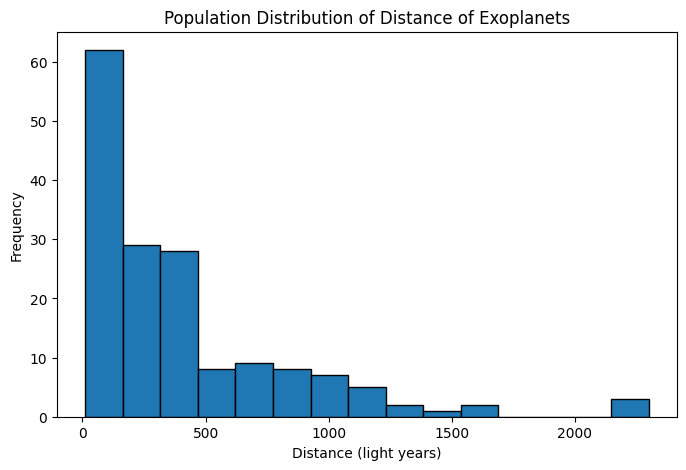

In [ ]:
# Plot population distribution

plt.figure(figsize=(8, 5))

plt.hist(distance_data, bins=15, edgecolor="black")

plt.title("Population Distribution of Distance of Exoplanets")
plt.xlabel("Distance (light years)")
plt.ylabel("Frequency")

plt.show()

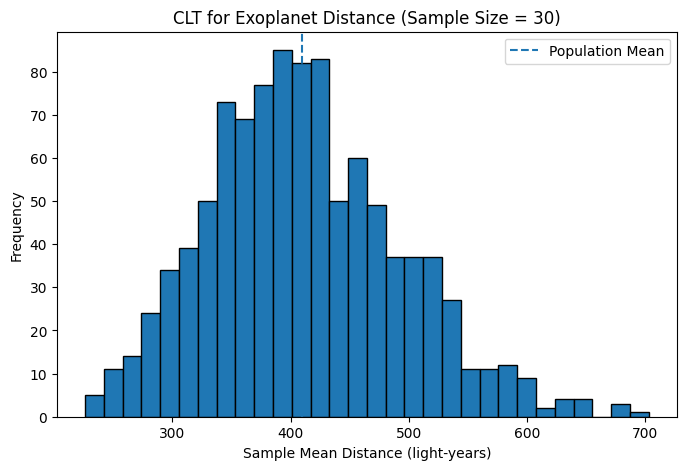

Sample Size: 30
Mean of Sample Means: 411.2891646
Standard Deviation of Sample Means: 81.2211715521341


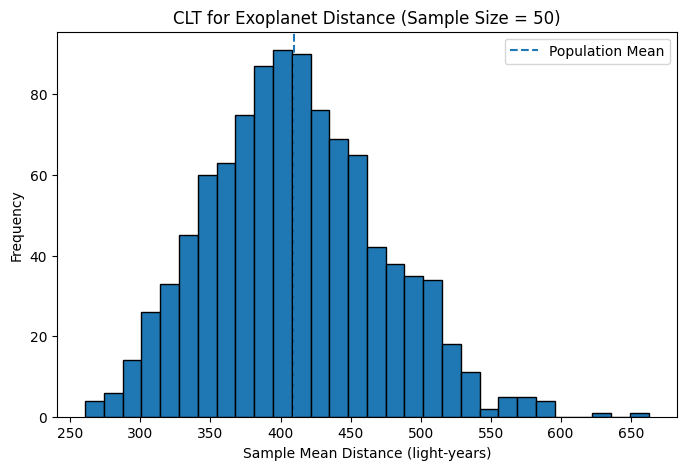

Sample Size: 50
Mean of Sample Means: 410.53907784
Standard Deviation of Sample Means: 61.321542642490854


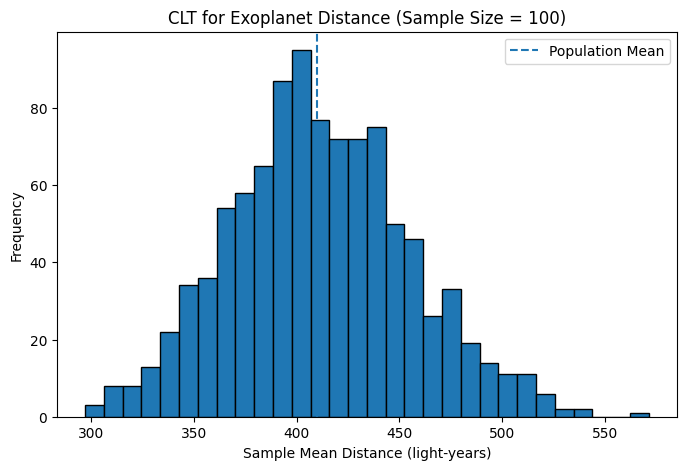

Sample Size: 100
Mean of Sample Means: 411.24913406
Standard Deviation of Sample Means: 43.85170052842045


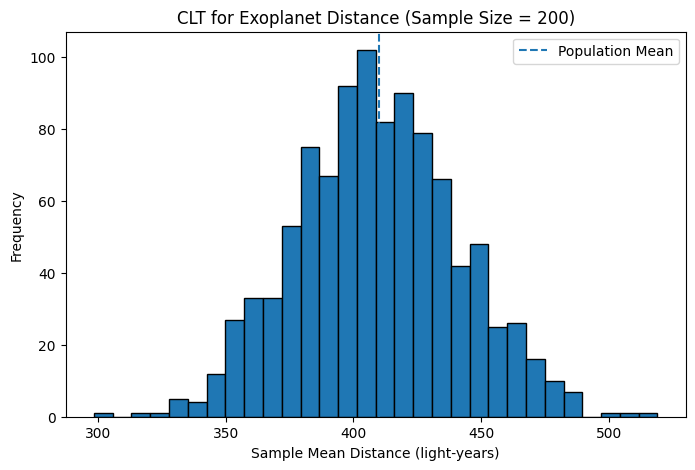

Sample Size: 200
Mean of Sample Means: 409.36270684
Standard Deviation of Sample Means: 31.5921648548678


In [ ]:
sample_sizes = [30, 50, 100, 200]
number_of_samples = 1000

for n in sample_sizes:
    sample_means = []

    for i in range(number_of_samples):
        sample = distance_data.sample(n=n, replace=True)
        sample_means.append(sample.mean())

    plt.figure(figsize=(8, 5))
    plt.hist(sample_means, bins=30, edgecolor="black")

    plt.axvline(population_mean, linestyle="--",
                label="Population Mean")

    plt.title("CLT for Exoplanet Distance (Sample Size = " + str(n) + ")")
    plt.xlabel("Sample Mean Distance (light-years)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

    print("Sample Size:", n)
    print("Mean of Sample Means:", np.mean(sample_means))
    print("Standard Deviation of Sample Means:", np.std(sample_means))

In [ ]:
# Estimate population mean

estimated_mean = np.mean(sample_means)

print("Actual Dataset Mean:", population_mean)
print("Estimated Population Mean:", estimated_mean)

print(
    "Absolute Error:",
    abs(population_mean - estimated_mean)
)

Actual Dataset Mean: 409.9393048780487
Estimated Population Mean: 409.36270684
Absolute Error: 0.5765980380487008


In [ ]:
standard_error = population_std / np.sqrt(n)

print("Sample Size:", n)
print("Mean of Sample Means:", np.mean(sample_means))
print("Standard Error:", standard_error)
print("Standard Deviation of Sample Means:", np.std(sample_means))

Sample Size: 200
Mean of Sample Means: 409.36270684
Standard Error: 31.053228556112852
Standard Deviation of Sample Means: 31.5921648548678


In [ ]:
# Hypothesis Testing

In [ ]:
# Select host star temperatures

data = clean_df["Host star temp. (K)"].dropna()

# Calculate basic statistics

n = len(data)

sample_mean = np.mean(data)

sample_std = np.std(data, ddof = 1)

print("Sample Size:", n)
print("Sample Mean:", sample_mean)
print("Sample Standard Deviation:", sample_std)

Sample Size: 164
Sample Mean: 5878.270731707317
Sample Standard Deviation: 3253.3523336692074


In [ ]:
# Use t distribution

confidence = 0.95

standard_error = sample_std / np.sqrt(n)

In [ ]:
# Calculate t critical value

t_critical = stats.t.ppf(
    (1 + confidence) / 2,
    df = n - 1
)

In [ ]:
# Margin of error

margin_error = t_critical * standard_error

In [ ]:
# Confidence interval

lower = sample_mean - margin_error
upper = sample_mean + margin_error

print("95% Confidence Interval:")

print("Lower Limit:", round(lower,2))
print("Upper Limit:", round(upper,2))

95% Confidence Interval:
Lower Limit: 5376.63
Upper Limit: 6379.91


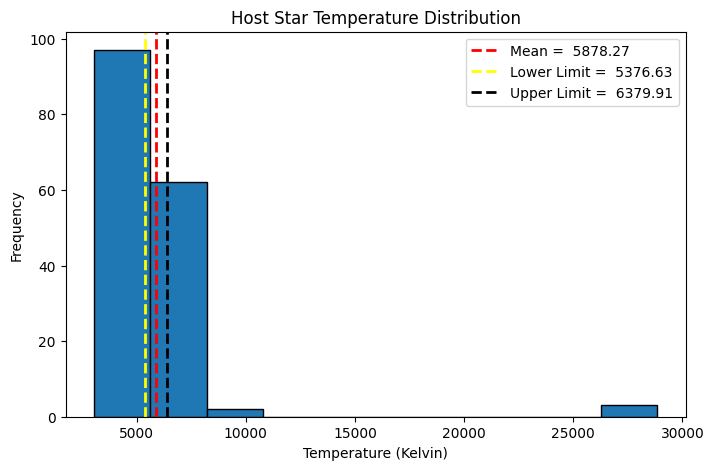

In [ ]:
# Graph for host star temperature distribution

plt.figure(figsize = (8,5))

plt.hist(data, bins = 10, edgecolor = "black")

plt.axvline(
    sample_mean,
    color = "red",
    linestyle = "--",
    linewidth = 2,
    label = f"Mean = {sample_mean : .2f}"
)

plt.axvline(
    lower,
    color = "yellow",
    linestyle = "--",
    linewidth = 2,
    label = f"Lower Limit = {lower : .2f}"
)

plt.axvline(
    upper,
    color = "black",
    linestyle = "--",
    linewidth = 2,
    label = f"Upper Limit = {upper : .2f}"
)

plt.title("Host Star Temperature Distribution")
plt.xlabel("Temperature (Kelvin)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

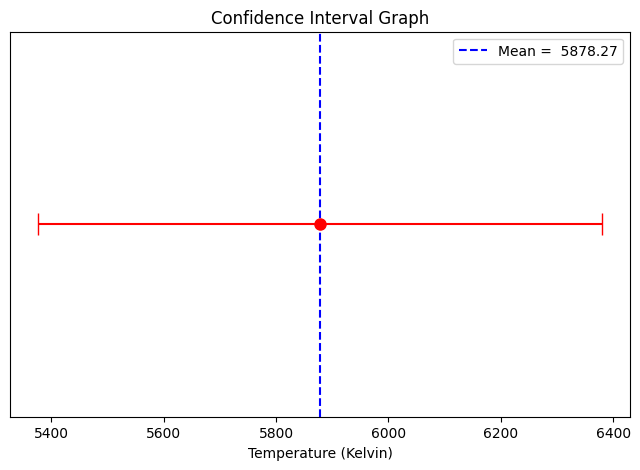

In [ ]:
# Confidence interval graph

plt.figure(figsize = (8,5))

plt.errorbar(
    sample_mean,
    1,
    xerr = margin_error,
    fmt = "o",
    color = "red",
    capsize = 8,
    markersize = 8
)

plt.axvline(
    sample_mean,
    color = "blue",
    linestyle = "--",
    label = f"Mean = {sample_mean : .2f}"
)

plt.title("Confidence Interval Graph")
plt.xlabel("Temperature (Kelvin)")
plt.yticks([])
plt.legend()

plt.show()

In [ ]:
# One Sample t - test

In [ ]:
# Hypothesized population mean

mu = 5000

# Perform one-sample t-test

t_statistic, p_value = stats.ttest_1samp(data, popmean=mu)

# Display results

print("One-Sample t-test:")
print("T-statistic:", t_statistic)
print("P-value:", p_value)

One-Sample t-test:
T-statistic: 3.457158052648108
P-value: 0.0006963571925202678


In [ ]:
# Make the decision

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The mean temperature is significantly different from 5000 K.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant difference in the mean temperature from 5000 K.")

Reject the null hypothesis
The mean temperature is significantly different from 5000 K.


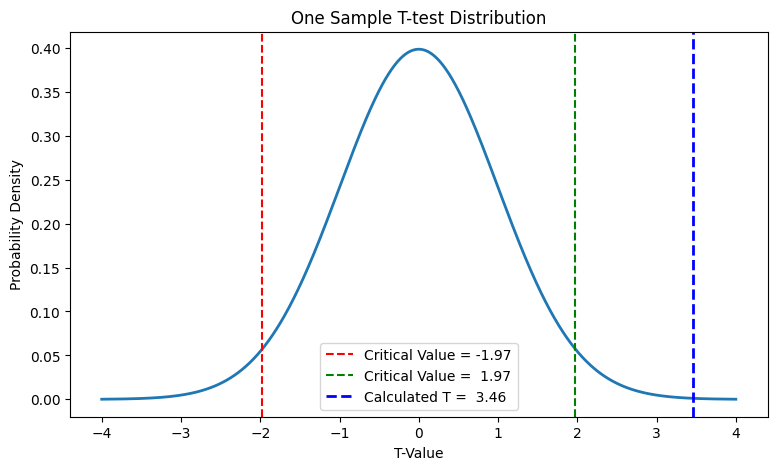

In [ ]:
x_t = np.linspace(-4, 4, 1000)

y_t = stats.t.pdf(
    x_t,
    df = n - 1
)

plt.figure(figsize = (9,5))

plt.plot(
    x_t,
    y_t,
    linewidth = 2
)

# Critical values for alpha = 0.05

t_critical_test = stats.t.ppf(
    1 - alpha / 2,
    df = n - 1
)

plt.axvline(
    -t_critical_test,
    color = "red",
    linestyle = "--",
    label = f"Critical Value = {-t_critical_test : .2f}"
)

plt.axvline(
    t_critical_test,
    color = "green",
    linestyle = "--",
    label = f"Critical Value = {t_critical_test : .2f}"
)

plt.axvline(
    t_statistic,
    color = "blue",
    linestyle = "--",
    linewidth = 2,
    label = f"Calculated T = {t_statistic : .2f}"
)

plt.xlabel("T-Value")
plt.ylabel("Probability Density")
plt.title("One Sample T-test Distribution")
plt.legend()

plt.show()

In [ ]:
# One Sample Z test

In [ ]:
# Set hypothesized mean and known population standard deviation

mu = 5000
population_std = 1000

In [ ]:
# Calculate Z statistic

z_score = ((sample_mean - mu) / (population_std / np.sqrt(n)))

# Calculate two tailed p value

p_value = 2 * (1 - stats.norm.cdf(np.abs(z_score)))

print("One Sample Z-test\n")
print("Z-score:", round(z_score, 4))
print("P-value:", round(p_value, 4))

One Sample Z-test

Z-score: 11.2474
P-value: 0.0


In [ ]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("The mean temperature is significantly different from 5000 K.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant difference in the mean temperature from 5000 K.")

Reject the null hypothesis
The mean temperature is significantly different from 5000 K.


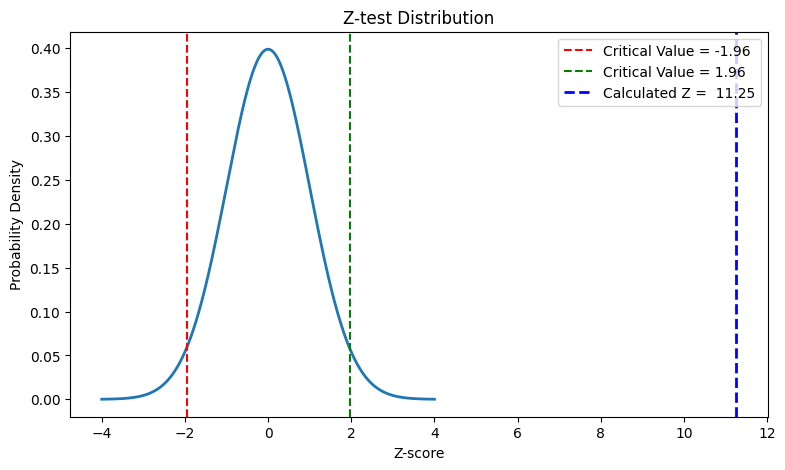

In [ ]:
# Graph for Z test

x = np.linspace(-4, 4, 1000)

y = stats.norm.pdf(x)

plt.figure(figsize = (9,5))

plt.plot(x, y, linewidth = 2)

# Crtical values for alpha = 0.05

z_critical = 1.96

plt.axvline(
    -z_critical,
    color = "red",
    linestyle = "--",
    label = "Critical Value = -1.96"
)

plt.axvline(
    z_critical,
    color = "green",
    linestyle = "--",
    label = "Critical Value = 1.96"
)

plt.axvline(
    z_score,
    color = "blue",
    linestyle = "--",
    linewidth = 2,
    label = f"Calculated Z = {z_score : .2f}"
)

plt.xlabel("Z-score")
plt.ylabel("Probability Density")
plt.title("Z-test Distribution")
plt.legend()

plt.show()

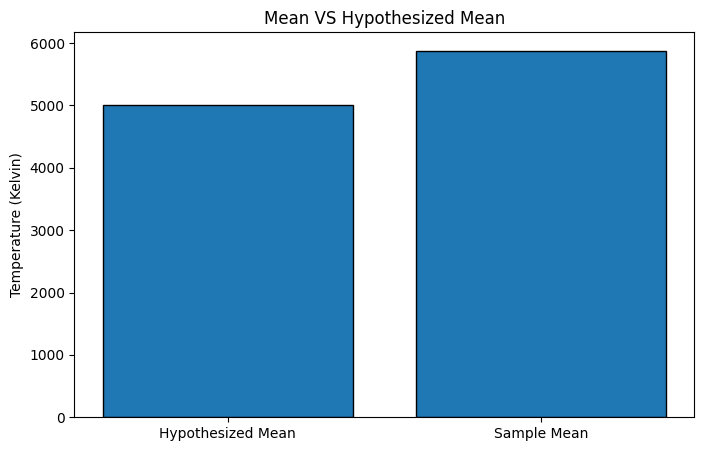

In [ ]:
# Mean VS Hypothesized Mean

plt.figure(figsize = (8,5))

values = [mu, sample_mean]
labels = ["Hypothesized Mean", "Sample Mean"]

plt.bar(labels, values, edgecolor = "black")

plt.title("Mean VS Hypothesized Mean")
plt.ylabel("Temperature (Kelvin)")

plt.show()

In [ ]:
# Two Sample t - Test

In [ ]:
# Select the two most common discovery methods

methods = clean_df["Discovery Method"].value_counts().head(2).index

# Get distance values for both groups

group1 = clean_df.loc[
    clean_df["Discovery Method"] == methods[0],
    "Distance (ly)"
].dropna()

group2 = clean_df.loc[
    clean_df["Discovery Method"] == methods[1],
    "Distance (ly)"
].dropna()

In [ ]:
# Calculate statistics

print("Discovery Method 1:", methods[0])
print("Sample Size 1:", len(group1))
print("Mean Distance 1:", np.mean(group1))
print("Standard Deviation 1:", np.std(group1, ddof=1))

print("\nDiscovery Method 2:", methods[1])
print("Sample Size 2:", len(group2))
print("Mean Distance 2:", np.mean(group2))
print("Standard Deviation 2:", np.std(group2, ddof=1))

Discovery Method 1: radial vel.
Sample Size 1: 103
Mean Distance 1: 200.84834951456313
Standard Deviation 1: 150.68489398961316

Discovery Method 2: transit
Sample Size 2: 54
Mean Distance 2: 720.7752962962963
Standard Deviation 2: 397.97313641020384


In [ ]:
# Perform two-sample t-test

t_statistic, p_value = stats.ttest_ind(
    group1, group2, equal_var=False
)

print("Two Sample T-Test")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Two Sample T-Test
T-statistic: -9.2587
P-value: 0.0


In [ ]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean distances between the two discovery methods.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant difference in the mean distances between the two discovery methods.")

Reject the null hypothesis
There is a significant difference in the mean distances between the two discovery methods.


In [ ]:
# Paired t Test

In [ ]:
# Select mass and radius for the same exoplanets

paired_data = clean_df[["Mass (MJ)", "Radius (RJ)"]].dropna()

mass = paired_data["Mass (MJ)"]
radius = paired_data["Radius (RJ)"]


print("Mean of Mass:", mass.mean())
print("Mean of Radius:", radius.mean())

mean_difference = mass.mean() - radius.mean()

print("Mean Difference:", mean_difference)

Mean of Mass: 1.6257504268292682
Mean of Radius: 1.1156689024390243
Mean Difference: 0.5100815243902439


In [ ]:
# Perform paired t test

t_statistic, p_value = stats.ttest_rel(mass, radius)

print("Paired T-Test")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Paired T-Test
T-statistic: 3.4373
P-value: 0.0007


In [ ]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean mass and radius between the two discovery methods.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant difference in the mean mass and radius between the two discovery methods.")

Reject the null hypothesis
There is a significant difference in the mean mass and radius between the two discovery methods.


In [ ]:
# Chi Square Test

In [ ]:
# Create a temporary dataframe using actual dataset columns

chi_df = clean_df[["Discovery Method", "Disc. year"]].dropna().copy()

# Group discovery years into decades

chi_df["Discovery Era"] = (
    (chi_df["Disc. year"] // 10) * 10
).astype(int).astype(str) + "s"

In [ ]:
# Create contingency table

contingency_table = pd.crosstab(
    chi_df["Discovery Method"],
    chi_df["Discovery Era"]
)

print("Contingency Table:")
print(contingency_table)

Contingency Table:
Discovery Era     1990s  2000s  2010s  2020s
Discovery Method                            
imaging               0      1      3      0
radial vel.           8     69     25      1
timing                3      0      0      0
transit               0     17     33      4


In [ ]:
# Perform Chi-Square Test

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("Chi-Square Test")
print("Chi-Square Statistic:", round(chi2, 4))
print("P-value:", round(p_value, 4))
print("Degrees of Freedom:", dof)

Chi-Square Test
Chi-Square Statistic: 74.3032
P-value: 0.0
Degrees of Freedom: 9


In [ ]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant association between the discovery method and the discovery era.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant association between the discovery method and the discovery era.")

Reject the null hypothesis
There is a significant association between the discovery method and the discovery era.


In [ ]:
# Anova Test

In [ ]:
# Select three common discovery methods

methods = clean_df["Discovery Method"].value_counts().head(3).index

group1 = clean_df.loc[
    clean_df["Discovery Method"] == methods[0],
    "Host star temp. (K)"
].dropna()

group2 = clean_df.loc[
    clean_df["Discovery Method"] == methods[1],
    "Host star temp. (K)"
].dropna()

group3 = clean_df.loc[
    clean_df["Discovery Method"] == methods[2],
    "Host star temp. (K)"
].dropna()

In [ ]:
# Display group information

print("Mean Temperature of", methods[0], ":", group1.mean())
print("Mean Temperature of", methods[1], ":", group2.mean())
print("Mean Temperature of", methods[2], ":", group3.mean())

Mean Temperature of radial vel. : 5292.8
Mean Temperature of transit : 5570.611111111111
Mean Temperature of imaging : 7874.25


In [ ]:
# Perform One-Way ANOVA

f_statistic, p_value = stats.f_oneway(
    group1, group2, group3
)

print("One-Way ANOVA Results")
print("F-statistic:", round(f_statistic, 4))
print("P-value:", round(p_value, 4))

One-Way ANOVA Results
F-statistic: 24.956
P-value: 0.0


In [ ]:
# Make the decision

if p_value < alpha:
    print("Reject the null hypothesis")
    print("There is a significant difference in the mean temperatures between the three discovery methods.")

else:
    print("Fail to reject the null hypothesis")
    print("There is no significant difference in the mean temperatures between the three discovery methods.")

Reject the null hypothesis
There is a significant difference in the mean temperatures between the three discovery methods.


In [ ]:
# Relationship Analysis - Covariance and Correlation
# Pearson and Spearman Correlation


 Host star mass (M☉) vs Host star temp. (K)

Covariance: 194.0272

Pearson Correlation: 0.148
Pearson p-value: 0.05855785383972737

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: 0.3254
Spearman p-value: 2.1252869889135827e-05

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


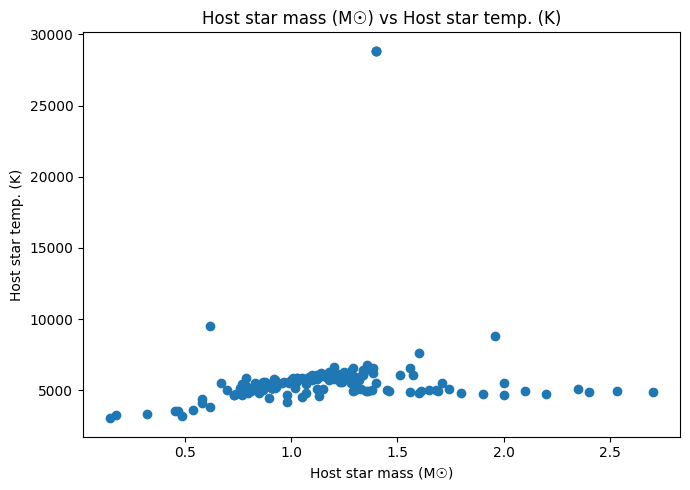


 Mass (MJ) vs Radius (RJ)

Covariance: 0.0773

Pearson Correlation: 0.1229
Pearson p-value: 0.11691081674858257

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: 0.2157
Spearman p-value: 0.005543296550168944

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


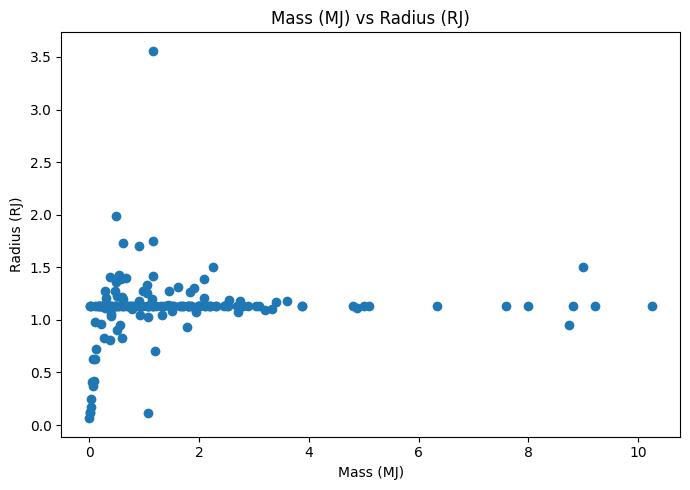


 Period (days) vs Semi-major axis (AU)

Covariance: 480470.3389

Pearson Correlation: 0.0567
Pearson p-value: 0.4711822914281495

Pearson Decision: Fail to Reject the Null Hypothesis
There is not a significant linear relationship.

Spearman Correlation: 0.9547
Spearman p-value: 3.663032440836634e-87

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


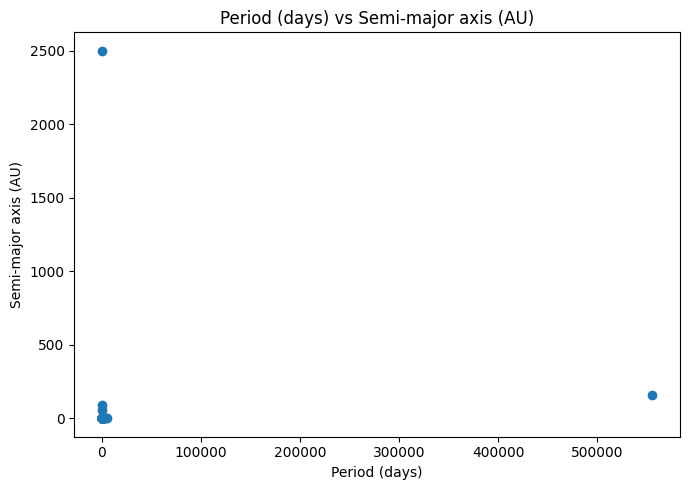


 Host star temp. (K) vs Distance (ly)

Covariance: 893409.5093

Pearson Correlation: 0.6253
Pearson p-value: 3.5433367576301963e-19

Pearson Decision: Reject the Null Hypothesis
There is a significant linear relationship.

Spearman Correlation: 0.2983
Spearman p-value: 0.0001048876335883357

Spearman Decision: Reject the Null Hypothesis
There is a significant monotonic relationship.


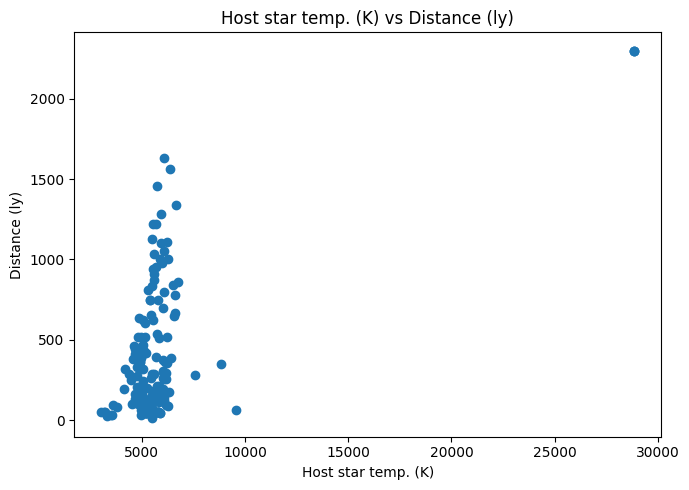

In [ ]:
# Define pairs of features

pairs = [
    ("Host star mass (M☉)", "Host star temp. (K)"),
    ("Mass (MJ)", "Radius (RJ)"),
    ("Period (days)", "Semi-major axis (AU)"),
    ("Host star temp. (K)", "Distance (ly)")
]

# Correlation analysis

for x, y in pairs:

    data = clean_df[[x, y]].dropna()

    print("\n", x, "vs", y)

    # Covariance

    covariance = data[x].cov(data[y])
    print("\nCovariance:", round(covariance, 4))

    # Pearson correlation

    pearson_corr, pearson_p = stats.pearsonr(data[x], data[y])

    print("\nPearson Correlation:", round(pearson_corr, 4))
    print("Pearson p-value:", pearson_p)

    if pearson_p < alpha:
        print("\nPearson Decision: Reject the Null Hypothesis")
        print("There is a significant linear relationship.")

    else:
        print("\nPearson Decision: Fail to Reject the Null Hypothesis")
        print("There is not a significant linear relationship.")


    # Spearman correlation

    spearman_corr, spearman_p = stats.spearmanr(data[x], data[y])

    print("\nSpearman Correlation:", round(spearman_corr, 4))
    print("Spearman p-value:", spearman_p)

    if spearman_p < alpha:
        print("\nSpearman Decision: Reject the Null Hypothesis")
        print("There is a significant monotonic relationship.")

    else:
        print("\nSpearman Decision: Fail to Reject the Null Hypothesis")
        print("There is not a significant monotonic relationship.\n")

    # Scatter plot

    plt.figure(figsize=(7, 5))
    plt.scatter(data[x], data[y])
    plt.title(x + " vs " + y)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()


 Period (days)
Minimum: 0.321962
Maximum: 555530.0
Median: 25.8
Skewness: 12.8


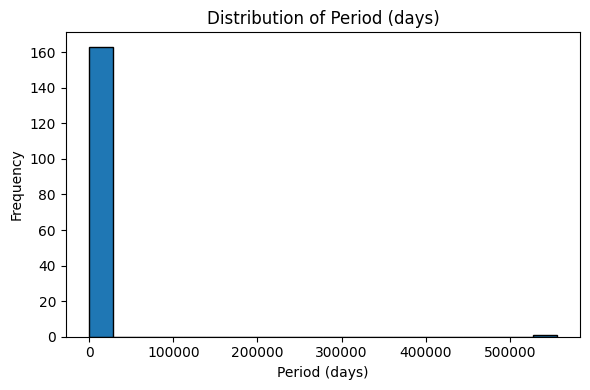


 Mass (MJ)
Minimum: 0.00172
Maximum: 10.25
Median: 1.077
Skewness: 2.52


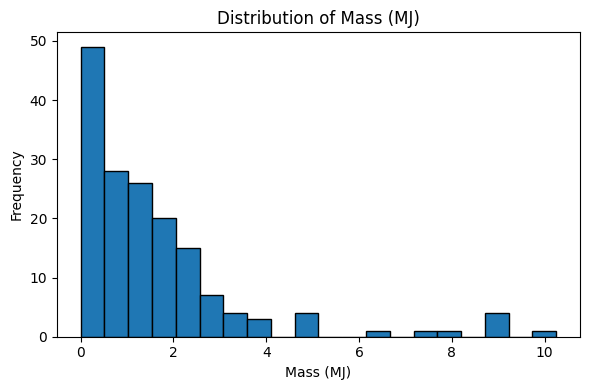


 Host star temp. (K)
Minimum: 3036.0
Maximum: 28856.0
Median: 5510.0
Skewness: 6.55


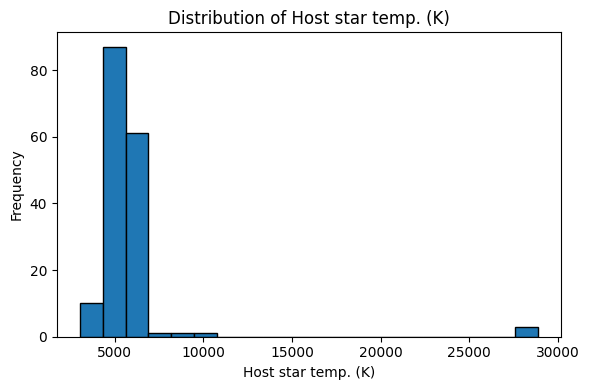

In [ ]:
# Choosing target variable

targets = [
    "Period (days)",
    "Mass (MJ)",
    "Host star temp. (K)"
]

for column in targets:
    print("\n", column)
    print("Minimum:", clean_df[column].min())
    print("Maximum:", clean_df[column].max())
    print("Median:", clean_df[column].median())
    print("Skewness:", round(clean_df[column].skew(), 2))

    plt.figure(figsize=(6, 4))
    plt.hist(clean_df[column], bins=20, edgecolor="black")
    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [ ]:
# Since Mass (MJ) has less skewness, we choose this feature as our dependent variable.

In [ ]:
# Multiple Linear Regression alongwith Lasso and RIdge Regression

In [ ]:
from sklearn.model_selection import train_test_split

# Independent variables

features = [
    "Period (days)",
    "Semi-major axis (AU)",
    "Host star mass (M☉)",
    "Host star temp. (K)"
]

# Dependent variable

target = "Mass (MJ)"

# Keep rows where mass was originally recorded

valid_rows = df[target].notna()

X = clean_df.loc[valid_rows, features].copy()
y = clean_df.loc[valid_rows, target].copy()

# Split data into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Total usable rows:", len(X))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Independent variables:", features)
print("Dependent variable:", target)

Total usable rows: 162
Training rows: 129
Testing rows: 33
Independent variables: ['Period (days)', 'Semi-major axis (AU)', 'Host star mass (M☉)', 'Host star temp. (K)']
Dependent variable: Mass (MJ)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create the Multiple Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train, y_train)

# Predict mass for the test data

linear_pred = linear_model.predict(X_test)

print("Multiple Linear Regression Results")
print("-" * 50)
print("Intercept:", round(linear_model.intercept_, 2))
print("Coefficients:", linear_model.coef_)

Multiple Linear Regression Results
--------------------------------------------------
Intercept: -1.0
Coefficients: [ 5.82765745e-04  3.32048694e-03  2.43926759e+00 -6.04803329e-05]


In [ ]:
# Scaling is useful for Lasso and Ridge

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import Ridge

# Create the Ridge Regression model

ridge_model = Ridge(alpha=1.0)

# Train the model using scaled data

ridge_model.fit(X_train_scaled, y_train)

# Predict planet mass

ridge_pred = ridge_model.predict(X_test_scaled)

print("Ridge Regression")
print("-" * 50)

print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))
print("Coefficients:", ridge_model.coef_)

Ridge Regression
--------------------------------------------------
Alpha: 1.0
Intercept: 1.71
Coefficients: [ 0.29898575  0.72123545  0.93593767 -0.17831541]


In [108]:
from sklearn.linear_model import Lasso

# Create the Lasso Regression model

lasso_model = Lasso(alpha=0.1)

# Train the model using scaled data

lasso_model.fit(X_train_scaled, y_train)

# Predict planet mass

lasso_pred = lasso_model.predict(X_test_scaled)

print("Lasso Regression")
print("-" * 50)

print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))
print("Coefficients:", lasso_model.coef_)

Lasso Regression
--------------------------------------------------
Alpha: 0.1
Intercept: 1.71
Coefficients: [ 0.21556623  0.59678389  0.82143055 -0.05697604]


In [110]:
# Decision Tree Regression

from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=3, random_state=42
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Decision Tree Regression")
print("-" * 50)

print("Maximum Depth:", tree_model.max_depth)

Decision Tree Regression
--------------------------------------------------
Maximum Depth: 3


In [112]:
# Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100, max_depth=3, random_state=42
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print("Random Forest Regression")
print("-" * 50)

print("Number of Trees:", forest_model.n_estimators)
print("Maximum Depth:", forest_model.max_depth)

Random Forest Regression
--------------------------------------------------
Number of Trees: 100
Maximum Depth: 3


In [113]:
prediction = {
    'Multiple Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
}

In [114]:
results = []

for model_name, prediction in prediction.items():

    mae = mean_absolute_error(y_test, prediction)

    mse = mean_squared_error(y_test, prediction)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, prediction)

    results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2
0,Multiple Linear Regression,1.013322,2.136823,1.461788,0.036732
1,Ridge Regression,1.012624,2.128709,1.459010,0.040390
2,Lasso Regression,1.046524,2.105753,1.451121,0.050738
3,Decision Tree Regression,1.034432,2.129510,1.459284,0.040029
4,Random Forest Regression,1.017217,1.822765,1.350098,0.178308


In [115]:
models = {
    'Multiple Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree Regression': tree_model,
    'Random Forest Regression': forest_model
}

In [116]:
best_model_name = results_df.loc[
    results_df['R2'].idxmax(), 'Model'
]

best_model1 = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest Regression


In [117]:
best_model1

RandomForestRegressor(max_depth=3, random_state=42)

In [118]:
import joblib

joblib.dump(best_model1, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

joblib.dump(best_model_name, 'best_model_name.pkl')

['best_model_name.pkl']

In [119]:
model = joblib.load('best_model.pkl')

scaler = joblib.load('scaler.pkl')

best_model_name = joblib.load('best_model_name.pkl')

In [120]:
def predict_mass(period, semi_major_axis, star_mass, star_temp):

    sample_data = pd.DataFrame({
        "Period (days)": [period],
        "Semi-major axis (AU)": [semi_major_axis],
        "Host star mass (M☉)": [star_mass],
        "Host star temp. (K)": [star_temp]
    })

    # Scale inputs only for models trained on scaled features

    if best_model_name in ["Ridge Regression", "Lasso Regression"]:
        sample_data = scaler.transform(sample_data)

    prediction = model.predict(sample_data)

    return f"Predicted Planet Mass: {prediction[0]:.4f} MJ"

In [121]:
import gradio as gr

interface = gr.Interface(
    fn=predict_mass,
    inputs=[
        gr.Number(label="Orbital Period (days)", value=10),
        gr.Number(label="Semi-major Axis (AU)", value=0.1),
        gr.Number(label="Host Star Mass (M☉)", value=1.0),
        gr.Number(label="Host Star Temperature (K)", value=5800)
    ],
    outputs="text",
    title="Exoplanet Mass Prediction System",
    description=(
        "Enter the orbital period, semi-major axis, host star mass, and host star temperature to predict an exoplanet's mass."
    )
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2ba1cb58d0b3d51a8f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
